# Numerical Methods

**Numerical methods** are the set of algorithms used to obtain approximate solutions to mathematical problems that are either impossible or impractical to solve analytically. The underlying idea is to replace a continuous mathematical problem with a finite set of arithmetic operations that a computer can execute efficiently.



## Root Finding Methods

**Root finding methods** are very popular due to the number of possible applications in the analysis of dynamic systems, especially in the non-linear regime. They can be formulated as follow:

Given a nonlinear function $ \textbf{f}:\mathbb R^n \rightarrow \mathbb R^n$, find $ \textbf{x}^*$ such that $f( \textbf{x}^*)=0$. For a scalar problem this simply becomes $f(x)=0$

### Bisection Method

This is the simplest root-finding algorithm. If $f(a)f(b)<0$ and $f(x)$ is continuous in $\left [ a,b \right ]$, the intermediate value theorem guarantees a root exists within the interval.

At each step, the algorithm calculates $c=\frac{a+b}{2}$ and $f(c)$ to get the sign of $f(a)f(c)<0$ and $f(c)f(b)<0$, then it keeps the half interval containing the sign change (either $\left [ a,c \right ]$ or $\left [ c,b \right ]$). The convergence rate is **linear**, and the error after $n$ iterations is

$$e_n \le \frac{b-a}{2^n}$$

It is useful when robustness is more important than speed, and is often used to initialize faster methods.

The example below implement the bisection method for the cubic function $f(x)=x^3-2x-5$. The root has value 2.09455148.

In [4]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from algorithms import *

######### Initial interval ############
a = 2
b = 4
#######################################

def f(x):
    return x**3 - 2*x - 5

root = bisection(f, a, b)

print(f"\nRoot found: {root:.12f}")

Iter |            a |            b |            c |         f(c) |    Rel.Error
--------------------------------------------------------------------------------
   1 |     2.000000 |     4.000000 |     3.000000 | 1.600000e+01 |          nan
   2 |     2.000000 |     3.000000 |     2.500000 | 5.625000e+00 | 2.000000e-01
   3 |     2.000000 |     2.500000 |     2.250000 | 1.890625e+00 | 1.111111e-01
   4 |     2.000000 |     2.250000 |     2.125000 | 3.457031e-01 | 5.882353e-02
   5 |     2.000000 |     2.125000 |     2.062500 | -3.513184e-01 | 3.030303e-02
   6 |     2.062500 |     2.125000 |     2.093750 | -8.941650e-03 | 1.492537e-02
   7 |     2.093750 |     2.125000 |     2.109375 | 1.668358e-01 | 7.407407e-03
   8 |     2.093750 |     2.109375 |     2.101562 | 7.856226e-02 | 3.717472e-03
   9 |     2.093750 |     2.101562 |     2.097656 | 3.471428e-02 | 1.862197e-03
  10 |     2.093750 |     2.097656 |     2.095703 | 1.286233e-02 | 9.319664e-04
  11 |     2.093750 |     2.095703 | 

### Newton-Raphson Method

This is by far the most popular numerical method for engineering analysis.Starting from $x_k$, one can approximate the function using a first-order Taylor expansion:

$$f(x) \approx f(x_k) + f'(x_k)(x-x_k)$$

Setting $f(x)=0$ yields 

$$x_{k+1} = x_k - \frac{f(x_k)} {f'(x_k)}$$

To get a gometrical interpretation, draw the tangent to the curve at $x_k$: the next estimate is where the tangent intersects the x-axis.

Near the solution the convergence rate is quadratic (the number of correct digits approximately doubles each iteration):

$$e_{k+1} \approx C e_k^2$$

Newton methods are very fast, but can diverge if the initial guess is poor or if the derivative is almost zero.

The example below uses the Newton metod to find roots of the cubic function $f(x)=x^3-2x-5$ (same as the previous example). In this case, we need to calcolate the derivative, which is $f'(x)=3x^2-2$



In [5]:
from algorithms import *

######### Initial interval ############
x0 = 2 # initial guess
#######################################

def f(x):
    return x**3 - 2*x - 5

def df(x):
    return 3*x**2 - 2

root = newton(f=f, df=df, x0=x0)

print(f"\nRoot found: {root:.12f}")

Iter |              x |           f(x) |      Rel.Error
------------------------------------------------------------
   1 |   2.1000000000 |   6.100000e-02 |   4.761905e-02
   2 |   2.0945681211 |   1.857232e-04 |   2.593317e-03
   3 |   2.0945514817 |   1.739761e-09 |   7.944138e-06

Converged on function tolerance.

Root found: 2.094551481698


### Secant Method

This method replaces the derivative with a finite difference:

$$f'(x_k) \approx \frac{f(x_k)-f(x_{k-1})} {x_k-x_{k-1}}$$

Substitution gives:

$$x_{k+1} = x_k - f(x_k) \frac{x_k-x_{k-1}} {f(x_k)-f(x_{k-1})}$$


In this case no derivatives are required, and the convergence order is $1.618$ (faster than bisection, slower than Newton). It is useful when the derivatives are difficult to obtain and/or the function evaluations are relatively cheap.

The example below uses the Newton metod to find roots of the cubic function $f(x)=x^3-2x-5$ (same as the previous example).

In [6]:
from algorithms import *

########### Initial guess #############
x0 = 2 
x1 = 3
#######################################

def f(x):
    return x**3 - 2*x - 5

root = secant(f, x0, x1)

print(f"\nRoot found: {root:.12f}")

Iter |              x |           f(x) |      Rel.Error
------------------------------------------------------------
   1 |   2.0588235294 |  -3.907999e-01 |   4.571429e-01
   2 |   2.0812636598 |  -1.472041e-01 |   1.078197e-02
   3 |   2.0948241461 |   3.043796e-03 |   6.473329e-03
   4 |   2.0945494310 |  -2.288658e-05 |   1.311571e-04
   5 |   2.0945514812 |  -3.512811e-09 |   9.788217e-07

Converged on function tolerance.

Root found: 2.094551481228



### Multidimensional Newton Method

Many engineering problems involve vectors instead of scalars. In this case the problem to solve can be written as 

$$ \textbf{f}\left ( \textbf{x} \right )=0 $$

, where $\textbf{x}$ and $\textbf{f}$ are $n$-dimensional vectors.

$$\textbf{x}=\begin{bmatrix} x_1\\ x_2\\ \vdots\\ x_n \end{bmatrix}, \textbf{f} = \begin{bmatrix} f_1\\ f_2\\ \vdots\\ f_n \end{bmatrix}$$

Instead of a single derivate, we define **Jacobian matrix** the grid of all first-order derivatives of $\textbf{f}$ respect to $\textbf{x}$:



$$J= \frac{\partial F} {\partial x} = \begin{bmatrix} \frac{\partial f_1}{\partial x_1} & \cdots & \frac{\partial f_1}{\partial x_n} \\ \vdots & \ddots & \vdots \\ \frac{\partial f_n}{\partial x_1} & \cdots & \frac{\partial f_n}{\partial x_n} \end{bmatrix}$$


Similarly to the scalar case, we get:

$$\textbf{x}_{k+1} =\textbf{x}_k -\frac{\textbf{f}(\textbf{x}_k)}{\textbf{J}_k}$$

## Numerical Integrators

### Fixed Step Integrators

A fixed-step integrator advances the solution of an ODE (Ordinary DIfferential Equation) using the same time increment $\Delta t$ at every step. Consider the first order ODE

$$\frac{dy}{dt} = f(t,y)$$

with initial condition

$$y(t0)=y0$$

The integration interval is divided into equally spaced points:

$$t_{n+1}​=t_n ​+ \Delta t$$

,where $\Delta t$ (step size) is chosen once at the beginning and never changes.

#### Euler Method

The simplest fixed-step integrator is **Forward Euler**:
$$y_{n+1} = y_n + \Delta t \, f(t_n,y_n)$$
The next value is calculated as the current value plus the derivative (fist order ODE) times the time step.


#### Runge-Kutta 4 (RK4) Method

A much more accurate fixed-step method is the classical **fourth-order Runge-Kutta (RK)** method. Runge-Kutta is a family of iterative numerical methods used to solve first order ODDEs.

Instead of calculating high-order derivatives (which are difficult to compute analytically), Runge-Kutta methods approximate higher-order Taylor series accuracy by evaluating the rate of change $f(t,y)$ at multiple intermediate trial points within a single step $\Delta t$.

The most famous member of this family is the 4th-Order Runge-Kutta (RK4) method. To step from $y_n$ to $y_(n+1)$ over interval $\Delta t$, RK4 takes a weighted average of four trial slopes ($k_1,k_2,k_3,k_4$):

$$\begin{aligned} k_1 &= f(t_n, y_n) && \text{(Slope at beginning of step)} \\ k_2 &= f\left(t_n + \frac{\Delta t}{2}, y_n + \frac{\Delta t}{2} k_1\right) && \text{(Trial slope at midpoint using } k_1\text{)} \\ k_3 &= f\left(t_n + \frac{\Delta t}{2}, y_n + \frac{\Delta t}{2} k_2\right) && \text{(Trial slope at midpoint using } k_2\text{)} \\ k_4 &= f(t_n + \Delta t, y_n + \Delta t k_3) && \text{(Trial slope at end of step using } k_3\text{)} \end{aligned}$$


The final state update uses a Simpson's-rule weighted average that gives double weight to the midpoint estimates:

$$y_{n+1} = y_n + \frac{\Delta t}{6} (k_1+2k_2+2k_3+k_4)$$

#### Example

A simple example is a free falling body (without drag) dynamic system. This is a second order ODE, which can be written as a system of two first order ODEs:

$$\frac{dh}{dt} = v$$
$$\frac{dv}{dt} = -g$$

The code below allows to visually check as the accuracy of the Euler method changes depending of the step size and as the RK4 provides way more accurate results.

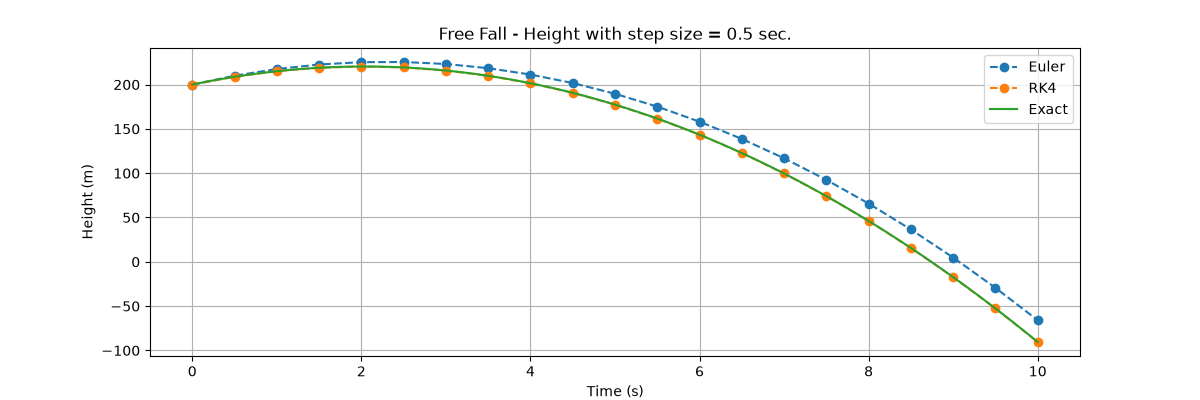

Euler final error:  224.52500000000003
RK4 final error:    200.00000000000006


In [7]:
from dynamic_systems import *
%matplotlib widget

###### Initial conditions ######
h0 = 200.0   # initial altitude
v0 = 20.0    # initial velocity (positive upward)
g = 9.81  # m/s²
######### Parameters ###########
step_size = 0.5
duration = 10
################################

init_state = [h0, v0]
time_span = [0, duration]
euler_vs_rk4_free_fall(init_state, g, step_size, time_span)

### Variable Step Integrators

A variable-step integrator is a numerical algorithm used to solve ordinary differential equations (ODEs) by automatically adjusting the step size $\Delta t$ as it progresses.

Instead of taking uniform time steps like a fixed-step method (e.g., standard Euler or RK4), a variable-step solver calculates the local error at each step. If the error is too high, it rejects the step and retries with a smaller h; if the error is well below tolerance, it increases h to take larger jumps and speed up computation.

#### Runge-Kutta 45 (RK45) Method

The most common approach uses embedded Runge-Kutta pairs (such as Dormand-Prince / RK45 or Bogacki-Shampine / RK23). At state $y_n$ and time $t_n$, the integrator computes two estimates of the next state using two different orders of accuracy (e.g., 4th-order $y_{n+1}^{(5)}$ and 5th-order $y_{n+1}^{(5)}$). Shared function evaluations are implemented to keep computational cost low.

Assuming $\Delta t$ is the currently used step size, the **local truncation error** $E$ is estimated as the difference between the high-order and low-order solutions of the previous integrations:

$$E = \Vert{} y_{n+1}^{(5)} - y_{n+1}^{(4)} \Vert{}$$

The estimated error E is compared against a user-defined threshold, usually calculated from absolute ($Tol_{abs}$) and relative ($Tol_{rel}$) tolerances:


$$Tol = Tol_{abs} + Tol_{rel} \cdot \Vert{} y_n \Vert{}$$

We have two options here:

1) $E \le Tol$: accept the step ($y_{n+1}=y_{n+1}^{(5)}$) and advance time using the current $\Delta t$ ($t_{n+1}=t_n + \Delta t$).
2) $E \ge Tol$: reject the step and recompute from $t_n$ by reducint the step size,


For case 2., the new step size ($\Delta t_{new}$) is calculated using asymptotic error scaling for an order-p method, the new step size is computed as:


$$ \Delta t_{new} = S\Delta t  \left ( \frac{1}{E} \right )^\frac{1}{5}$$

, where $S$ is a safety factor to prevent repeated rejections (normally between 0.8 and 0.9, e.g., 0.84).

The plot below shows the steps taken by the RK45 integrator for the same free falling body example as above. Note as the number of steps greatly depends on the maximum step size. In case of max_step_size = np.inf there are no limits in the step size.



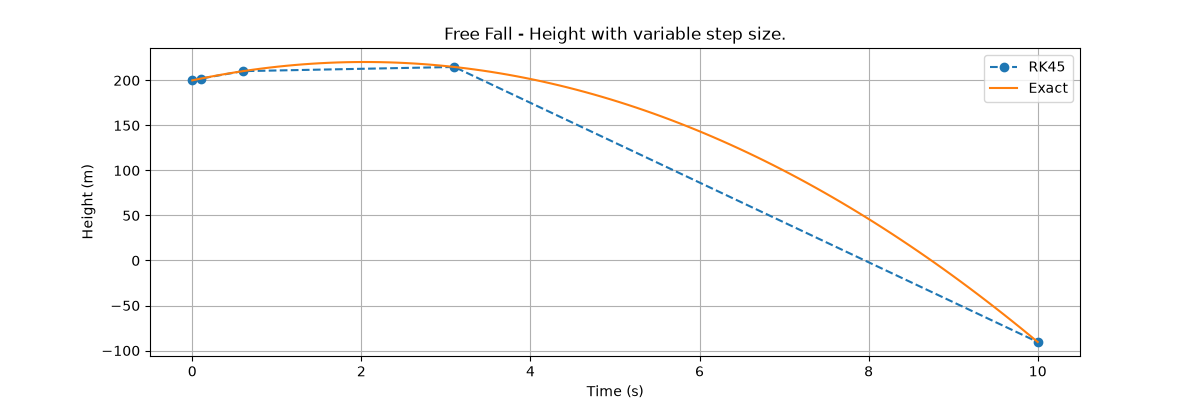

In [8]:
from dynamic_systems import *
%matplotlib widget

######### Parameters ###########
max_step_size = np.inf
################################

rk45_free_fall(init_state, g, time_span, max_step_size)

### Example - Evaluating $\Delta V$ for Orbit Transfers

A satellite is running on a circular orbit with radius $r_0 = 6900$ $km$ and velocity $V_0=7.6$ $km/sec$. When a $\Delta V$ is applied, its semimajor axis $a$ increases accordingly with the following function:

$$ a=\left [ \frac{1}{\frac{2}{r_0}-\frac{\left ( V_0 + \Delta V \right )^{2}}{\mu}} \right ]$$

The (nonlinear) relationship between $\Delta V$ and $a$ is highlited in the plot below:

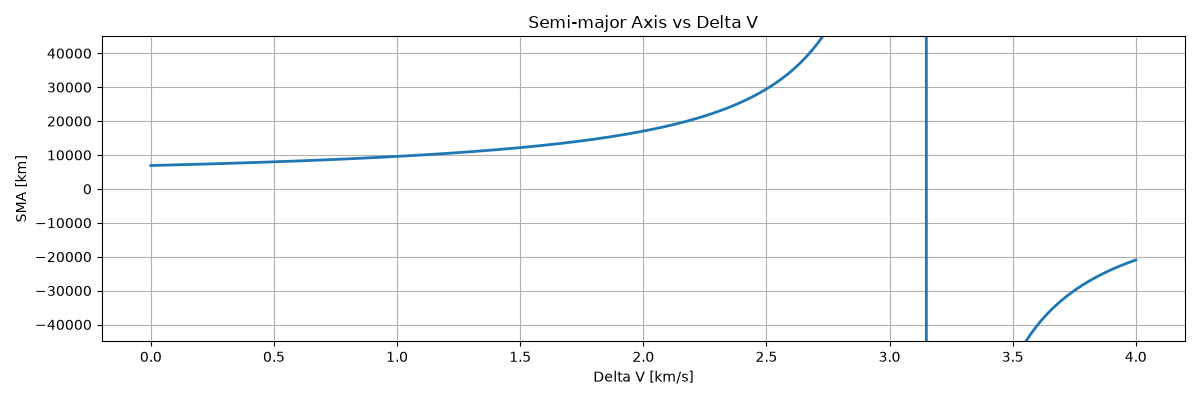

In [9]:
plot_sma_vs_delta_v()

Note as the function has a singularity at some point; when the applied $\Delta V$ is higher than this value, the orbit becomes hyperbolic and the semimajor axis becomes negative. As analysts, we need to evaluate how much $\Delta V$ is need to get $a = 10000$ $km$ and $42164$ $km$ respectively.

Using both Secant and Newton methods, check how they perform depending on the target value and the parameters used to initialize the methods.

In [10]:
######### Parameters ###########
a_target = 10000   # SMA to reach, km
dv_min = 0.5 # min independent variable for secant method
dv_max = 1.5 # max independent variable for secant method
dv_0 = 0.5   # initial guess for Newton method
################################

def f(x, a_target=a_target):
    return  (1 / ((2 / 6900) - ((7.6 + x)**2 / 398600.4418))) - a_target

def df(x):
    return (2 * (7.6 + x))/(398600.4418 * (2/6900 - (7.6 + x)**2/398600.4418)**2)

print('--- Secant Method ---')
root = secant(f, dv_min, dv_max)
print(f"\nRoot found: {root:.12f}")
print('--- Newton Method ---')
root = newton(f, df, x0=dv_0)
print(f"\nRoot found: {root:.12f}")

--- Secant Method ---
Iter |              x |           f(x) |      Rel.Error
------------------------------------------------------------
   1 |   0.9805095564 |  -4.894087e+02 |   5.298168e-01
   2 |   1.0757600262 |  -1.011990e+02 |   8.854249e-02
   3 |   1.1005900510 |   6.012506e+00 |   2.256065e-02
   4 |   1.0991975642 |  -6.961838e-02 |   1.266821e-03
   5 |   1.0992135031 |  -4.733767e-05 |   1.450032e-05
   6 |   1.0992135140 |   3.692548e-10 |   9.866339e-09

Converged on function tolerance.

Root found: 1.099213513993
--- Newton Method ---
Iter |              x |           f(x) |      Rel.Error
------------------------------------------------------------
   1 |   1.2783011326 |   8.574592e+02 |   6.088559e-01
   2 |   1.1150203936 |   6.953801e+01 |   1.464374e-01
   3 |   1.0993369087 |   5.386358e-01 |   1.426631e-02
   4 |   1.0992135215 |   3.282920e-05 |   1.122504e-04
   5 |   1.0992135140 |   0.000000e+00 |   6.842361e-09

Converged on function tolerance.

Root foun